# Claude binary label balance by partition

Compare **adoption (1)** and **retention (0)** among usable natural-condition labels in each frozen partition. Agreement, unclassifiable responses, and technical failures are excluded from the binary percentages.

Run all cells from the repository root or `notebooks/`. Set `RUN_NAME` below to choose a labeling run. Completed partitions use their final binary CSV and summary; running partitions use a snapshot of complete raw JSONL rows and are explicitly marked **partial**. Missing partitions are shown as unavailable. Rerun to refresh after labeling finishes.

The figure is saved as **SVG** under `reports/figures/claude_validation/<RUN_NAME>/binary_label_balance.svg`. Test labels are shown for descriptive reporting; reserve test performance for final evaluation.

In [1]:
from pathlib import Path
import csv
import json
import warnings
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
from IPython.display import display

REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "scripts/run_claude_validation.py").is_file()),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError("Run this notebook from within the repository.")

RUN_NAME = "mixed_final_001"
LABEL_ROOT = REPO_ROOT / "results/claude_validation" / RUN_NAME
SVG_PATH = REPO_ROOT / "reports/figures/claude_validation" / RUN_NAME / "binary_label_balance.svg"
PARTITIONS = ("train", "validation", "test")


In [2]:
def read_partition(partition):
    run_dir = LABEL_ROOT / partition
    raw_path = run_dir / "raw_results.jsonl"
    csv_path = run_dir / "binary_labels.csv"
    summary_path = run_dir / "summary.json"
    selected_path = run_dir / "selected_episodes.json"
    selected = len(json.loads(selected_path.read_text())) if selected_path.exists() else None
    counts = Counter()
    processed = 0

    if summary_path.exists():
        summary = json.loads(summary_path.read_text())
        if summary["partition"] != partition or summary["condition_filter"] != "natural":
            raise ValueError(f"Unexpected partition or condition in {summary_path}")
        with csv_path.open(newline="") as handle:
            for row in csv.DictReader(handle):
                if row["partition"] != partition or row["critic_condition"] != "natural":
                    raise ValueError(f"Unexpected partition or condition in {csv_path}")
                if row["eligible_primary"].lower() == "true":
                    target = int(row["primary_target"])
                    if target not in (0, 1):
                        raise ValueError(f"Invalid binary target: {target}")
                    counts[target] += 1
        processed = summary["n_episodes"]
        selected = selected if selected is not None else processed
        status = "Complete"
    elif raw_path.exists():
        # Limit reading to the file size at the start: don't chase an active writer.
        # A truncated final line is ignored and picked up on the next refresh.
        with raw_path.open("rb") as handle:
            snapshot = handle.read(raw_path.stat().st_size)
        lines = snapshot.splitlines(keepends=True)
        for index, line in enumerate(lines):
            try:
                row = json.loads(line)
            except json.JSONDecodeError:
                if index == len(lines) - 1 and not line.endswith(b"\n"):
                    warnings.warn(f"{partition}: ignoring an unfinished final row")
                    continue
                raise
            if row["partition"] != partition or row["critic_condition"] != "natural":
                raise ValueError(f"Unexpected partition or condition in {raw_path}")
            processed += 1
            if row.get("eligible_primary"):
                target = row["primary_target"]
                if target not in (0, 1):
                    raise ValueError(f"Invalid binary target: {target}")
                counts[target] += 1
        status = "Partial"
    else:
        status = "Unavailable"

    usable = counts[0] + counts[1]
    return {
        "Partition": partition,
        "Status": status,
        "Selected": selected,
        "Processed": processed,
        "Usable": usable,
        "Excluded": processed - usable,
        "Adoption": counts[1],
        "Retention": counts[0],
        "Adoption %": 100 * counts[1] / usable if usable else float("nan"),
        "Retention %": 100 * counts[0] / usable if usable else float("nan"),
    }

balance = pd.DataFrame(read_partition(partition) for partition in PARTITIONS)
display(balance.style.format({
    "Selected": "{:,.0f}", "Processed": "{:,.0f}", "Usable": "{:,.0f}",
    "Excluded": "{:,.0f}", "Adoption": "{:,.0f}", "Retention": "{:,.0f}",
    "Adoption %": "{:.1f}%", "Retention %": "{:.1f}%",
}, na_rep="—"))


,Partition,Status,Selected,Processed,Usable,Excluded,Adoption,Retention,Adoption %,Retention %
0,train,Complete,"72,846","72,846","25,556","47,290","13,015","12,541",50.9%,49.1%
1,validation,Complete,"9,105","9,105","3,227","5,878","1,645","1,582",51.0%,49.0%
2,test,Complete,"9,112","9,112","3,223","5,889","1,642","1,581",50.9%,49.1%


Saved SVG: reports/figures/claude_validation/mixed_final_001/binary_label_balance.svg


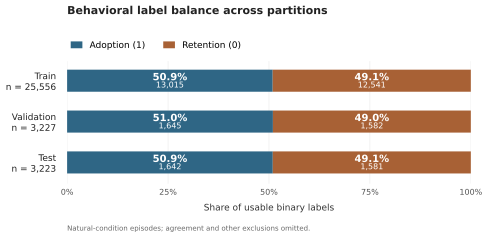

In [3]:
# Percentages are normalized within usable binary labels, not all episodes.
# Use a compact layout sized for a paper's two-column figure width.
with plt.rc_context({
    "svg.fonttype": "none",  # Preserve editable vector text.
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelcolor": "#333333",
    "xtick.color": "#555555",
    "ytick.color": "#222222",
}):
    fig, ax = plt.subplots(figsize=(7.2, 3.35))
    fig.subplots_adjust(left=0.20, right=0.98, top=0.74, bottom=0.23)
    adoption_color, retention_color = "#2F6685", "#A86135"
    y = list(range(len(balance)))
    adoption = balance["Adoption %"].fillna(0).to_numpy()
    retention = balance["Retention %"].fillna(0).to_numpy()
    ax.barh(y, adoption, color=adoption_color, height=0.54, label="Adoption (1)")
    ax.barh(y, retention, left=adoption, color=retention_color, height=0.54,
            label="Retention (0)")

    tick_labels = []
    for i, row in balance.iterrows():
        status = "" if row["Status"] == "Complete" else f" ({row['Status'].lower()})"
        tick_labels.append(f"{row['Partition'].title()}{status}\nn = {row['Usable']:,}")
        for width, left, count in (
            (adoption[i], 0, row["Adoption"]),
            (retention[i], adoption[i], row["Retention"]),
        ):
            if width >= 12:
                center = left + width / 2
                ax.text(center, i - 0.075, f"{width:.1f}%", ha="center", va="center",
                        color="white", fontsize=10, weight="bold")
                ax.text(center, i + 0.115, f"{count:,}", ha="center", va="center",
                        color="white", fontsize=8)
        if not row["Usable"]:
            ax.text(50, i, "No usable labels", ha="center", va="center", color="#666666")

    ax.set_yticks(y, tick_labels)
    ax.set_ylim(len(balance) - 0.48, -0.48)
    ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100])
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.set_xlabel("Share of usable binary labels", labelpad=7)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E5E5E5", linewidth=0.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="y", length=0, pad=11, labelsize=9)
    ax.tick_params(axis="x", length=0, pad=5, labelsize=8)
    fig.suptitle("Behavioral label balance across partitions", x=0.20, y=0.97,
                 ha="left", fontsize=11, weight="bold", color="#222222")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.06), ncol=2, frameon=False,
              borderaxespad=0, handlelength=1.3, handleheight=0.8,
              columnspacing=2, fontsize=9)
    note = "Natural-condition episodes; agreement and other exclusions omitted."
    if (balance["Status"] != "Complete").any():
        note += " Partial results marked."
    fig.text(0.20, 0.035, note, fontsize=7, color="#666666", ha="left")
    SVG_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(SVG_PATH, format="svg", bbox_inches="tight", pad_inches=0.08,
                facecolor="white")
    plt.show()

print(f"Saved SVG: {SVG_PATH.relative_to(REPO_ROOT)}")
